# EDA: resistencia a compresión del hormigón

## 1. Introducción y objetivo

Analizamos los datos de **1.030 ensayos** de hormigón para describir su resistencia y su relación con la mezcla y la edad. Los ingredientes están medidos en kg/m³, la edad en días y la resistencia en MPa (megapascales). Fuente: `Concrete_Readme.txt` (I-Cheng Yeh).

## 2. Carga y perfilado

Leemos el Excel original. Si falta `xlrd`, se puede utilizar la copia CSV incluida con la entrega.

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

archivo_excel = Path("Concrete_Data.xls")
archivo_csv = Path("Concrete_Data_convertido.csv")
try:
    df = pd.read_excel(archivo_excel)
except ImportError:
    if not archivo_csv.exists():
        raise ImportError("Instala xlrd con %pip install xlrd o coloca Concrete_Data_convertido.csv en esta carpeta")
    df = pd.read_csv(archivo_csv)

nombres = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water", "Superplasticizer",
           "Coarse Aggregate", "Fine Aggregate", "Age", "Concrete compressive strength"]
df.columns = nombres
objetivo = "Concrete compressive strength"
df.head()

C:\Users\cotar\AppData\Local\Temp\ipykernel_19452\2205769377.py:9: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(archivo_excel)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [8]:
print("Filas y columnas:", df.shape)
df.info()
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Filas y columnas: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB
Valores nulos: 0
Filas duplicadas: 25


**Resultado:** 1.030 filas, 9 columnas numéricas y ningún nulo. Hay 25 filas idénticas, que podrían corresponder a ensayos repetidos.

## 3. Limpieza y preparación

Revisamos valores negativos, edades fuera del rango documentado y posibles valores atípicos de resistencia (método del rango intercuartílico, IQR).

In [9]:
print("Valores negativos:", (df < 0).sum().sum())
print("Edades fuera de 1–365 días:", (~df["Age"].between(1, 365)).sum())
q1, q3 = df[objetivo].quantile([0.25, 0.75])
iqr = q3 - q1
atipicos = ((df[objetivo] < q1 - 1.5 * iqr) |
            (df[objetivo] > q3 + 1.5 * iqr)).sum()
print("Posibles valores atípicos de resistencia:", atipicos)

Valores negativos: 0
Edades fuera de 1–365 días: 0
Posibles valores atípicos de resistencia: 4


**Decisión:** no hay valores negativos ni edades fuera del intervalo. Hay 4 posibles valores atípicos; se conservan junto con las 25 filas repetidas porque no consta que sean errores. Los ceros en ingredientes pueden ser válidos.

## 4. Análisis exploratorio

### 4.1. Univariante: distribución de la resistencia

count    1030.00
mean       35.82
std        16.71
min         2.33
25%        23.71
50%        34.44
75%        46.14
max        82.60
Name: Concrete compressive strength, dtype: float64


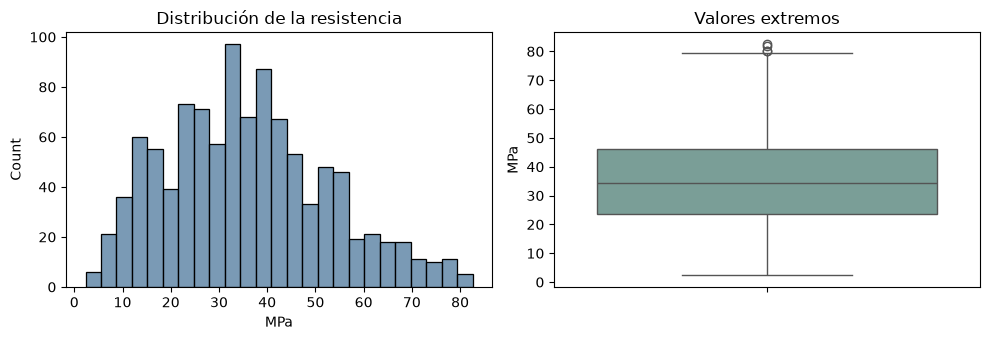

In [10]:
print(df[objetivo].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(data=df, x=objetivo, bins=25, color="#4E799D", ax=axes[0])
axes[0].set(title="Distribución de la resistencia", xlabel="MPa")
sns.boxplot(y=df[objetivo], color="#74A49B", ax=axes[1])
axes[1].set(title="Valores extremos", ylabel="MPa")
plt.tight_layout()
plt.show()

**Hallazgo:** resistencia media de **35,82 MPa** y mediana de **34,44 MPa**, con valores entre **2,33 y 82,60 MPa**.

### 4.2. Bivariante: cemento y edad frente a resistencia

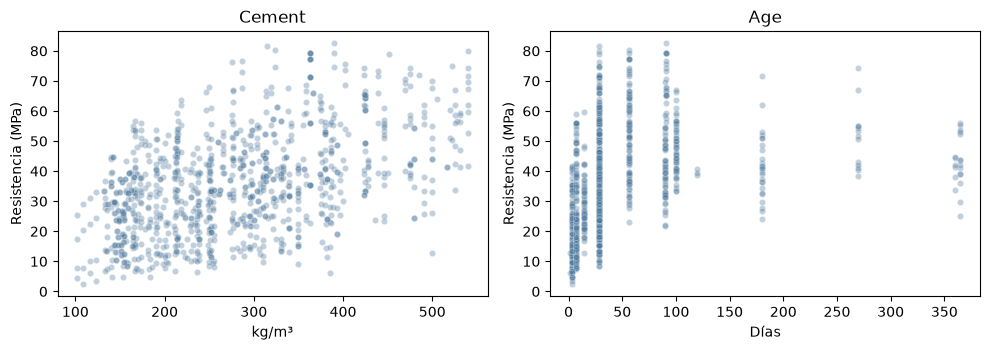

Correlación cemento-resistencia: 0.498
Correlación edad-resistencia: 0.329


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, variable in zip(axes, ["Cement", "Age"]):
    sns.scatterplot(data=df, x=variable, y=objetivo, alpha=0.35, s=20, color="#4E799D", ax=ax)
    ax.set(xlabel="kg/m³" if variable == "Cement" else "Días", ylabel="Resistencia (MPa)", title=variable)
plt.tight_layout()
plt.show()
print("Correlación cemento-resistencia:", round(df["Cement"].corr(df[objetivo]), 3))
print("Correlación edad-resistencia:", round(df["Age"].corr(df[objetivo]), 3))

**Hallazgo:** la resistencia presenta asociación positiva con el cemento (**r = 0,498**) y con la edad (**r = 0,329**). Son asociaciones, no pruebas de causalidad.

### 4.3. Multivariante: correlaciones entre todas las variables

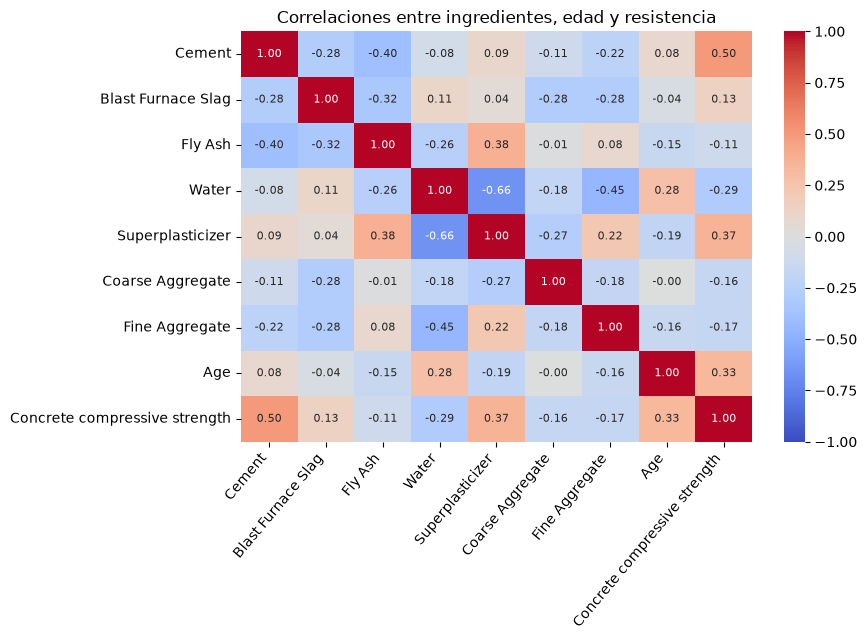

In [12]:
correlaciones = df.corr(numeric_only=True)
plt.figure(figsize=(9, 6.5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot_kws={"size":8})
plt.title("Correlaciones entre ingredientes, edad y resistencia")
plt.xticks(rotation=50, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Hallazgo:** la resistencia se asocia positivamente con el cemento (**r = 0,498**) y el superplastificante (**r = 0,366**), y negativamente con el agua (**r = −0,290**). Los ingredientes también se relacionan entre sí, por lo que deben interpretarse en conjunto.

## 5. Conclusiones

- La resistencia varía mucho entre ensayos (**2,33–82,60 MPa**).
- **Cemento** y **edad** muestran asociación positiva con la resistencia; el **agua**, negativa.
- No hay valores ausentes. Conservamos las repeticiones y valores extremos al no poder confirmar que sean errores.

El EDA (Análisis Exploratorio de Datos) identifica tendencias, pero no demuestra qué variable causa la resistencia.